# IHLT Project
Students : Oscar Cubeles, Valentin-Gabriel Soumah


This project tackles the **SemEval-2012 Semantic Textual Similarity (STS) task** by developing models that can actually understand how similar two sentences and comparing these predictions to a gold-standard. We're using linguistic features across three main categories which are: match-based features, lexical features and syntactic features. We develop and then select select subsets of features across different models to analyze how the models perform on unseen data.

# Table of Contents

**[1. Data Preparation](#1-data-preparation)**
- **[1.1 Loading Data](#11-loading-data)** - Loading MSRpar, MSRvid, and SMTeuroparl datasets
- **[1.2 Preprocessing](#12-preprocessing)** - Text cleaning, contraction replacement, and normalization
- **[1.3 Generating Features](#13-generating-features)** - Computing match-based, lexical, and syntactic features

**[2. Model Selection](#2-model-selection)**
- **[2.1 Ridge Regression](#21-ridgre-regression)** - Linear baseline with hyperparameter tuning
- **[2.2 Random Forest Regression](#22-random-forest-regression)** - Ensemble method with grid search
- **[2.3 Support Vector Regression](#23-support-vector-regression)** - Non-linear baseline model

**[3. Lexical vs Syntactic vs All Features](#3-lexical-vs-syntactic-vs-all-features)**
- **[3.1 Lexical Features](#31-lexical-features)** - Performance using only lexical similarity features
- **[3.2 Syntactic Features](#32-syntactic-features)** - Performance using only syntactic similarity features
- **[3.3 Performance comparison across feature categories](#33-performance-comparison-across-feature-categories)**

**[4. Feature Selection](#4-feature-selection)**
- **[4.1 Backward Feature Elimination](#41-backward-feature-elimination)** - Iterative feature removal across all models
- **[4.2 Cross-Model Feature Interpretation](#42-cross-model-feature-interpretation)** - Ridge coefficients, RF importance, correlations
- **[4.3 Linking the Evidence Together](#43-linking-the-evidence-together)** - Final feature removal decisions
- **[4.4 Training Final Models on Selected Features](#44-training-final-models-on-selected-features)** - Retrained models with filtered features

**[5. Tests on Test Set](#5-tests-on-test-set)**
- **[5.1 Models Evaluation](#51-models-evaluation)** - Performance comparison on held-out test data

**[6. Development Process and Discussion](#6-development-process-and-discussion)**


---

In [2]:
# Base Libraries
import os
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# NLP Libraries
import spacy
from scipy.stats import pearsonr

# Import Our Python Modules
import features as ft
import preprocessing as pp
import feature_selection as fs
from load_data import load_files, merge_datasets 

# ML Libraries
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.inspection import permutation_importance

importlib.reload(ft)
importlib.reload(pp)

nlp = spacy.load("en_core_web_md")

## 1. Data Preparation

### 1.1 Loading Data

In [ ]:
# Loading the train data and merging them into a single dataframe
data_path = 'data/train/train/'
df_paraphrases = load_files(data_path+'STS.gs.MSRpar.txt', data_path+'STS.input.MSRpar.txt')
df_vid = load_files(data_path+'STS.gs.MSRvid.txt', data_path+'STS.input.MSRvid.txt')
df_europarl = load_files(data_path+'STS.gs.SMTeuroparl.txt', data_path+'STS.input.SMTeuroparl.txt') 

In [4]:
df = merge_datasets([df_paraphrases, df_vid , df_europarl])
df.head()

,sentence1,sentence2,score
0,But other sources close to the sale said Viven...,But other sources close to the sale said Viven...,4.00
1,Micron has declared its first quarterly profit...,Micron's numbers also marked the first quarter...,3.75
2,The fines are part of failed Republican effort...,"Perry said he backs the Senate's efforts, incl...",2.80
3,"The American Anglican Council, which represent...","The American Anglican Council, which represent...",3.40
4,The tech-loaded Nasdaq composite rose 20.96 po...,The technology-laced Nasdaq Composite Index <....,2.40


### 1.2 Preprocessing

Before computing the features, we do some simple preprocessing steps to improve the similarity computation. It is important to note that here we do not remove stopwords as they are meaningful for the pos taggers, thus removal of stopwords is computed on features that require so. 

1. All dates and times are not normalized
2. All hyphens "-", slashes "/" and angular brackets (< and >) are removed;
1. The currency values are simplified, e.g., $US1234 to $1234 (simple);
4. Replace contractions. e.g: n’t with not, ’m with am


In [5]:
df_preprocessed = pp.preprocess_dataframe(df)
df_preprocessed.head(15)
print(df_preprocessed.iloc[11]["sentence1"])

Replacements were made:
Before: Chavez said investigators feel confident they've got "at least one of the fires resolved in that regard."
After:  Chavez said investigators feel confident they have got "at least one of the fires resolved in that regard."
Replacements were made:
Before: Plofsky said the commission won't investigate because the three year statute of limitations has expired.
After:  Plofsky said the commission will not investigate because the three year statute of limitations has expired.
Replacements were made:
Before: In two weeks, he'll probably send out Peace Rules in the Preakness.
After:  In two weeks, he will probably send out Peace Rules in the Preakness.
Replacements were made:
Before: Still, he said, "I'm absolutely confident we're going to have a bill."
After:  Still, he said, "I am absolutely confident we are going to have a bill."
Replacements were made:
Before: "I'm absolutely confident we're going to have a bill," Frist, R Tenn., said Thursday.
After:  "I am

### 1.3 Generating Features

In [6]:
match_based_features = [ 
            ft.word_jaccard_distance, 
            ft.compute_number_similarity,
            ft.date_similarity,
            ft.word_bigram_jaccard, 
            ft.word_trigram_jaccard,
]

lexical_features = [ft.synset_jaccard_distance,
            ft.weighted_wordnet_similarity,
            ft.sentence_path_similarity,
            ft.sentence_lch_similarity,
            ft.sentence_wup_similarity,
            ft.sentence_lin_similarity,
            ft.sentence_path_similarity_max,
            ft.sentence_lch_similarity_max,
            ft.sentence_wup_similarity_max,
            ft.sentence_lin_similarity_max,
            ft.sentence_rarity_similarity,
            ft.stem_jaccard_distance,
            ft.lemma_jaccard_distance,
            ft.lemma_bigram_jaccard, 
            ft.lemma_trigram_jaccard
]

syntactic_features = [ft.pos_jaccard_distance,
            ft.sentence_length_difference,
            ft.longest_common_subsequence, 
            ft.longest_common_substring,
            ft.greedy_string_tiling,
            ft.pos_lev_distance,
            ft.dep_lev_distance,
            ft.ner_jaccard,
            ft.ner_presence,
]

match_based_features_names = [func.__name__ for func in match_based_features]
lexical_match_features_names = [func.__name__ for func in lexical_features] + match_based_features_names
syntactic_match_features_names = [func.__name__ for func in syntactic_features] + match_based_features_names
features = match_based_features  + lexical_features + syntactic_features

From all the features that we have designed, those have been divided into 3 categories: 
- **Match-based features**: Those features do not rely on any external resources nor annotations, they are computed purely based on the immediate form of the sentences and their tokens. 

     - **Word Unigram distance, Bigram and Trigram Jaccard Similarity**: Measures sentences comparing the overlap of word sequences using Jaccard distance for unigrams and similarity for bigrams and trigrams. For example, unigrams (`["alex", "played"]`), bigrams (`["alex played"]`), and trigrams (`["alex played football"]`) these freatures capture shared words and short sequences of words between sentences.
     - **Number Similarity**: Computes number similarity even if numbers are in word format. Also, computing with dice similarity to give more importance to intersections (reward more small overlaps)
     - **Date Similarity**: Finds all potential date objects in both sentences and computes the similarity based on the time distance between dates. E.g: Same date returns 1


---
- **Lexical Features**: Those features leverage external lexical ressources (wordnet or more basic lexicons for lemmatization)
     - **Synset Jaccard Distance**:  Measures sentence similarity based on the overlap of word senses (synsets) derived using WSD. First uses the Lesk algorithm to assign synsets to words, then computes the Jaccard similarity between the sets of synsets for each sentence. 
     - **Weighted WordNet Similarity** and **Sentence Rarity Similarity**: Features that measure sentence similarity by comparing token overlap, with weights based on word rarity (from the Brown corpus) and semantic depth in WordNet. Rare and semantically specific words contribute more to the similarity score by having high weights.
     - **Lemma Unigram Distance, Bigram and Trigram Jaccard Similarity**: Measures sentence similarity by comparing the overlap of word sequences after lemmatizing the words in the sentences. Similar to the word-based unigram, bigram, and trigram comparisons, but instead of raw words, the words are reduced to their base forms (lemmas). For example, after lemmatizing, `["playing"]` and `["played"]` both become `["play"]`, allowing for comparison of shared lemmas.

    - **Sentence Path, LCH, WUP, and Lin Similarity**: These features compute semantic similarity between sentences using different WordNet metrics. :
      - **Path**: Path-based similarity
      - **LCH**: Leacock-Chodorow similarity
      - **WUP**: Wu-Palmer similarity
      - **Lin**: Lin similarity based on information content

        - **Aggregation (Mean vs Max)** Since the above metrics are initially word-level, computing them on sentence-level implies an asymetric computation where each word from senta is matched against its most similar word from sentb. All of those max word level similarity are then averaged (sim(senta, sentb)). Because of this, there is a need to agreate sim(sent1) and sim(sent2) to have a symetric feature. This is why each of the 4 above features have 2 versions, depending on the agregation method used :
          - **`mean`**: Default, which averages sim(sent1) and sim(sent2)
          - **`max`**: Selects the highest similarity score between sim(sent1, sent2) and sim(sent2, sent1)

---

- **Syntactic features**: Those feature harness the annotations made by NLP annotation tools (parsing, pos-tagging etc). In our case, all the annotations are provided by spacy NLP pipeline.
     - **Sentence Length similarity**: Absolute difference in sentence lengths divided by the maximum length. We considered syntactical because it reflects a sentence’s structure and complexity, longer sentences often have more clauses or phrases.
     
     - **POS Jaccard Distance and POS Levenshtein Distance**: Measure similarity between sentences based on **POS tags**. Jaccard distance considers overlap of POS tags as a set, while Levenshtein distance measures the minimum edits needed to transform one POS sequence into another.  
     - **Dependency Label Distance**: Computes the Levenshtein distance between sequences of dependency labels (`nsubj`, `obj`, `ROOT`, etc.), measuring the minimum edits to transform one sequence into another and capturing syntactic structure differences.
     - **Longest Common Subsequence (LCS) Similarity**: Measures sentence similarity by finding the longest sequence of words that appear in order in both sentences (not necessarily contiguous) and normalizing by the length of the longer sentence. For example, between `"I love playing very competitive football"` and `"She was playing football today"`, the LCS `"playing football"` is detected, giving a normalized similarity of 0.333.  

     - **Longest Common Substring (LCSubstr) Similarity**: Measures similarity by finding the longest contiguous sequence of words that appear in the same order in both sentences, normalized by the length of the longer sentence. For instance, between `"I love playing very competitive football"` and `"She was playing football today"`, the contiguous substring `"playing"` is the longest match.


     - **Greedy String Tiling**: Measures sentence similarity by finding the longest non-overlapping matching token sequences of at least a minimum length, marking them as used. For example, between `"I love playing football"` and `"She loves playing football"`, the matched tile `"playing football"` contributes to the similarity score.

     
     - **Named Entity Presence and Named Entity Distance**:  
        - **Presence**: Binary feature indicating whether either sentence contains named entities (e.g., `PERSON`, `ORG`, `DATE`).  
        - **Distance**: Measures similarity of named entity types between sentences using Jaccard distance. Considered syntactic/semantic because spacy's named entity recognition is built upon the pos labels and parsing tree.

In [7]:
X_raw = ft.compute_features(df_preprocessed, features, feature_dir='data/features_train')
y = df_preprocessed['score']
X_raw.head()


Loading cached feature: data/features_train/word_jaccard_distance.csv
Loading cached feature: data/features_train/compute_number_similarity.csv
Loading cached feature: data/features_train/date_similarity.csv
Loading cached feature: data/features_train/word_bigram_jaccard.csv
Loading cached feature: data/features_train/word_trigram_jaccard.csv
Loading cached feature: data/features_train/synset_jaccard_distance.csv
Loading cached feature: data/features_train/weighted_wordnet_similarity.csv
Loading cached feature: data/features_train/sentence_path_similarity.csv
Loading cached feature: data/features_train/sentence_lch_similarity.csv
Loading cached feature: data/features_train/sentence_wup_similarity.csv
Loading cached feature: data/features_train/sentence_lin_similarity.csv
Loading cached feature: data/features_train/sentence_path_similarity_max.csv
Loading cached feature: data/features_train/sentence_lch_similarity_max.csv
Loading cached feature: data/features_train/sentence_wup_similari

,word_jaccard_distance,compute_number_similarity,date_similarity,word_bigram_jaccard,word_trigram_jaccard,synset_jaccard_distance,weighted_wordnet_similarity,sentence_path_similarity,sentence_lch_similarity,sentence_wup_similarity,...,lemma_trigram_jaccard,pos_jaccard_distance,sentence_length_difference,longest_common_subsequence,longest_common_substring,greedy_string_tiling,pos_lev_distance,dep_lev_distance,ner_jaccard,ner_presence
0,0.437500,0.0,0.0,0.210526,0.105263,0.736842,0.631071,0.682672,1.931610,0.747434,...,0.050000,0.000000,0.178571,0.607143,0.500000,0.549020,9,10,0.666667,1
1,0.555556,1.0,0.0,0.000000,0.000000,0.636364,0.470290,0.727072,2.159410,0.805886,...,0.000000,0.500000,0.333333,0.266667,0.200000,0.240000,8,8,0.000000,1
2,0.615385,0.0,0.0,0.066667,0.000000,0.615385,0.399372,0.581032,2.433686,0.665476,...,0.076923,0.333333,0.000000,0.375000,0.250000,0.250000,11,14,0.666667,1
3,0.352941,0.0,0.0,0.300000,0.142857,0.550000,0.693230,0.751382,2.259175,0.816322,...,0.263158,0.000000,0.307692,0.653846,0.653846,0.772727,9,9,0.500000,1
4,0.863636,0.0,0.0,0.045455,0.000000,0.933333,0.158507,0.339469,1.624476,0.462040,...,0.000000,0.000000,0.166667,0.166667,0.055556,0.000000,11,13,0.750000,1


After computing the features, we apply normalization to ensure that all features are on the same scale. We keep the scaler to transform the test set later.

Then, we split the train data into train and validation. Train data will be used for training and cross validation (see below), while validation data will be used to assess the generalization ability of the selected models.

In [8]:
# Scale features
scaler = MinMaxScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns)

# Split data
X_train, X_val, y_train, y_val, df_preprocessed_train, df_preprocessed_val = train_test_split(
    X, y, df_preprocessed,  test_size=0.1, random_state=42
)

## 2. Model Selection 

In this section, we evaluate three regression algorithms as initial baselines for our prediction task. These models were selected because they offer complementary advantages in terms of interpretability, robustness, and modeling capacity. The **goal** of this section is to establish **initial benchmark performances** and identify which model families are most promising **before moving to deeper feature analysis and selection**. 

Additionally, our work does not focus on exploring all the models from the wide range of model families available in the literature that could be used for this task, but rather on analyzing the features, how they are combined and selected to improve the correlation with the provided gold standard. For this reason, we selected just one representative model from each major family considered (ensemble, linear, and SVM), without aiming to identify the best-performing model within each family, but simply to evaluate how different families behave under the same feature configurations.

The models are the following:

`Ridge Regression` serves as our most basic linear baseline. Its main strength lies in its interpretability: the learned coefficients provide immediate insight into the influence of each feature. Ridge is also computationally lightweight and offers a simple reference point against which more complex models can be compared.

`Random Forest Regression` is included because it naturally captures non-linear interactions between features, is robust to noise, and provides reliable permutation-based feature importance. This makes it a strong general-purpose model and a natural candidate for evaluating which features contribute the most.

`Support Vector Regression (SVR)` is a classic, high-performing model known for its ability to produce strong results without extensive fine-tuning. SVR often performs well on medium-sized datasets, making it a natural choice in our context as a stable, widely-used machine learning baseline.

For all three models, we apply grid-search hyperparameter tuning combined with 5-fold cross-validation. This is done to ensure a fair comparison across models,
robust performance estimates and meaningful insight into how each model behaves when using all available features.



In [9]:
def pearson_corr(model, X_val, y_val):
    preds = model.predict(X_val)
    return preds, pearsonr(y_val, preds)[0]

### 2.1 Ridge Regression

In [10]:
# Ridge Regression
ridge_param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100],
    "fit_intercept": [True, False],
    "solver": ["auto", "svd", "cholesky", "lsqr"],
}

ridge_gs = GridSearchCV(
    Ridge(random_state=42),
    ridge_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

ridge_gs.fit(X_train, y_train)
best_ridge_all = ridge_gs.best_estimator_
_, corr_ridge_all = pearson_corr(best_ridge_all, X_val, y_val)

### 2.2 Random Forest Regression

In [11]:
# Random Forest Regression
rf_param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
}

rf_gs = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

rf_gs.fit(X_train, y_train)
best_rf_all = rf_gs.best_estimator_
_, corr_rf_all = pearson_corr(best_rf_all, X_val, y_val)

### 2.3 Support Vector Regression

In [12]:
# Support Vector Regression (SVR)
svr_param_grid = {
    "C": [0.1, 1, 10],
    "epsilon": [0.01, 0.1],
    "kernel": ["rbf"],
    "gamma": ["scale", "auto"]
}

svr_gs = GridSearchCV(
    SVR(),
    svr_param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=0
)

svr_gs.fit(X_train, y_train)
best_svr_all = svr_gs.best_estimator_
_, corr_svr_all = pearson_corr(best_svr_all, X_val, y_val)

In [13]:
print("\nFinal Best Params:")
print("Ridge Best Params:", ridge_gs.best_params_)
print("Random Forest Best Params:", rf_gs.best_params_)
print("SVR Best Params:", svr_gs.best_params_)

print("\nFinal Results on Validation Set:")
print("Ridge Pearson Corr on Validation:", corr_ridge_all)
print("Random Forest Pearson Corr on Validation:", corr_rf_all)
print("SVR Pearson Corr on Validation:", corr_svr_all)


Final Best Params:
Ridge Best Params: {'alpha': 0.1, 'fit_intercept': False, 'solver': 'svd'}
Random Forest Best Params: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
SVR Best Params: {'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}

Final Results on Validation Set:
Ridge Pearson Corr on Validation: 0.7671703475478384
Random Forest Pearson Corr on Validation: 0.8537015455936158
SVR Pearson Corr on Validation: 0.833349662664564


## 3. Lexical vs Syntactic vs All Features



In the previous section, we trained our baseline models using the full feature set, which includes match-based, lexical, and syntactic similarity features. While this gives us an overall impression of model performance, it does not reveal which group of features contributes most to predictive accuracy.

To better understand the role of each feature category, we train the three models using:

- **Only lexical features**

- **Only syntactic features**

- **All features combined** (Already done in the previous section) 

This serves three purposes:

1) **Attribution of predictive power**:
We can see whether meaning-based (lexical) or structure-based (syntactic) features drive model performance.

2) **Diagnosing redundancy and noise**:
If a model performs almost as well with a small subset of features, this suggests redundancy or noise in the full set.

3) **Feature-engineering insights**:
Large performance gaps between feature groups highlight what future feature engineering should focus on.

This analysis provides a deeper understanding of why certain models perform better and helps guide our later feature-selection work.

In [14]:
# Dictionary storing all results
model_performance = {}  # model_name -> Pearson correlation

def train_and_score(model, param_grid, X_train, y_train, X_val, y_val, name):
    gs = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring="r2",
        cv=5,
        n_jobs=-1,
        verbose=0
    )
    gs.fit(X_train, y_train)
    best_model = gs.best_estimator_
    _, corr = pearson_corr(best_model, X_val, y_val)
    model_performance[name] = corr
    print(f"{name}: Validation Pearson={corr:.4f} \nParams={gs.best_params_}\n")
    return best_model, corr

### 3.1 Lexical Features

In [15]:
# Train set to train the model and validation set to evaluate it
X_train_lex = X_train[lexical_match_features_names]
X_val_lex   = X_val[lexical_match_features_names] 

# Ridge Regression (Lexical Features)
best_ridge_lex, corr_ridge_lex = train_and_score(
    Ridge(random_state=42), ridge_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "Ridge (Lexical)"
)

# Random Forest Regression (Lexical Features)
best_rf_lex, corr_rf_lex = train_and_score(
    RandomForestRegressor(random_state=42), rf_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "RandomForest (Lexical)"
)

# Support Vector Regression (Lexical Features)
best_svr_lex, corr_svr_lex = train_and_score(
    SVR(), svr_param_grid,
    X_train_lex, y_train, X_val_lex, y_val,
    "SVR (Lexical)"
)

Ridge (Lexical): Validation Pearson=0.7023 
Params={'alpha': 0.01, 'fit_intercept': False, 'solver': 'auto'}

RandomForest (Lexical): Validation Pearson=0.8237 
Params={'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

SVR (Lexical): Validation Pearson=0.7886 
Params={'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}



### 3.2 Syntactic Features

In [16]:
# Train set to train the model and validation set to evaluate it
X_train_syn = X_train[syntactic_match_features_names]
X_val_syn   = X_val[syntactic_match_features_names]

# Ridge Regression (Syntactic Features)
best_ridge_syn, corr_ridge_syn = train_and_score(
    Ridge(random_state=42), ridge_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "Ridge (Syntactic)"
)

# Random Forest Regression (Syntactic Features)
best_rf_syn, corr_rf_syn = train_and_score(
    RandomForestRegressor(random_state=42), rf_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "RandomForest (Syntactic)"
)

# Support Vector Regression (Syntactic Features)
best_svr_syn, corr_svr_syn = train_and_score(
    SVR(), svr_param_grid,
    X_train_syn, y_train, X_val_syn, y_val,
    "SVR (Syntactic)"
)


Ridge (Syntactic): Validation Pearson=0.6861 
Params={'alpha': 0.01, 'fit_intercept': True, 'solver': 'lsqr'}

RandomForest (Syntactic): Validation Pearson=0.8353 
Params={'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

SVR (Syntactic): Validation Pearson=0.7885 
Params={'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}



### 3.3 Performance comparison across feature categories

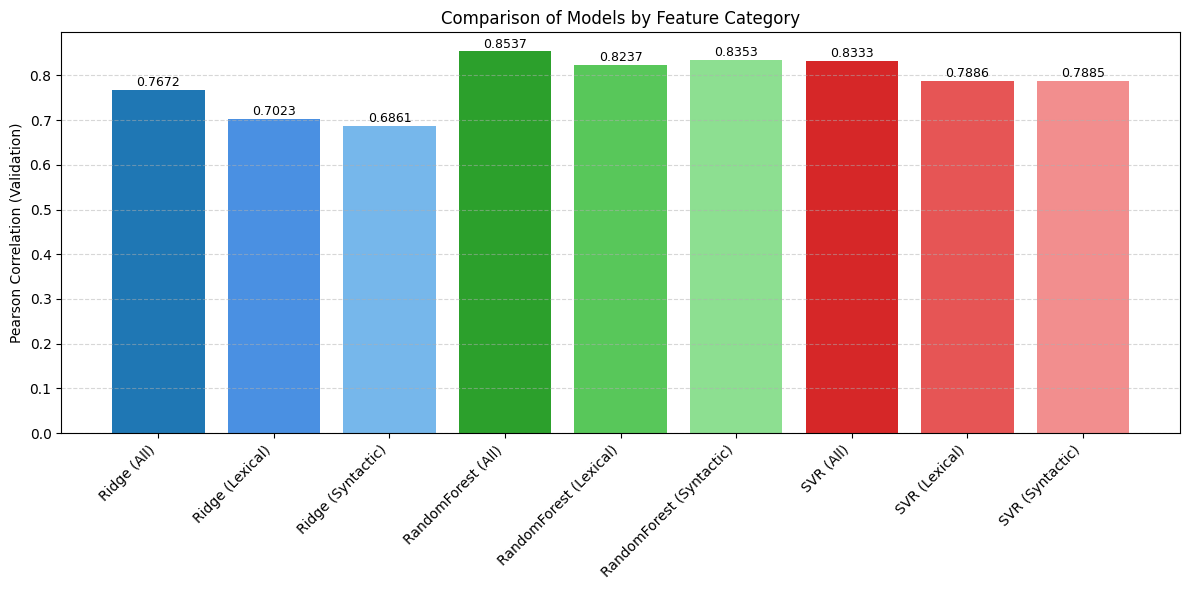

In [17]:
model_performance = {
    "Ridge (All)": corr_ridge_all,
    "Ridge (Lexical)": corr_ridge_lex,
    "Ridge (Syntactic)": corr_ridge_syn,

    "RandomForest (All)": corr_rf_all,
    "RandomForest (Lexical)": corr_rf_lex,
    "RandomForest (Syntactic)": corr_rf_syn,

    "SVR (All)": corr_svr_all,
    "SVR (Lexical)": corr_svr_lex,
    "SVR (Syntactic)": corr_svr_syn,
}

color_map = {
    "Ridge (All)":        "#1f77b4",
    "Ridge (Lexical)":    "#4a90e2",
    "Ridge (Syntactic)":  "#76b7eb",

    "RandomForest (All)":       "#2ca02c",
    "RandomForest (Lexical)":   "#58c75a",
    "RandomForest (Syntactic)": "#8ddf91",

    "SVR (All)":        "#d62728",
    "SVR (Lexical)":    "#e65555",
    "SVR (Syntactic)":  "#f28e8e",
}

labels = list(model_performance.keys())
scores = list(model_performance.values())
colors = [color_map[label] for label in labels]

plt.figure(figsize=(12, 6))
bars = plt.bar(labels, scores, color=colors)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Pearson Correlation (Validation)")
plt.title("Comparison of Models by Feature Category")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Add numeric labels on top of bars
for bar, score in zip(bars, scores):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.002, f"{score:.4f}", 
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

If we analize the results, there is a clear pattern, in all three models having all features rather than just Lexical or Syntactic performs better. Being SVR and Random Forest with all the features the best models with almost a 0.85 correlation in both cases. 

However, it is also true that across the three models the results from all features, just Lexical features or just Syntactical ones are quite aligned in the sense that there is no big gap between them. Also, it is worth mentioning that Syntactic features perform slightly better for SVR and Random Forest and the opposite happens for the Ridge Regression. 

To deepen the analysis we will perform more detailed feature selection in order to enhance validation accuracy.

## 4. Feature selection

As we mentioned in the previous section, not all of features contribute equally to the prediction. Some may be redundant, some may introduce noise, and some simply do not generalize well beyond the training folds. Eliminating such features often improves robustness, reduces overfitting, and helps interpretability.

To achieve this, we pursued a **two-step feature-selection strategy** where we first do a **Backward Feature Elimination** and then **Cross-checking with Correlation and Feature Importance** in order to select the more meaningful features.

1) First, we applied  **backward elimination** which iteratively removes features and evaluates whether this removal improves (or does not harm) the validation Pearson correlation. Since each model has different learning biases, this process highlights **model-specific redundancies** and gives a richer picture of which features are consistently useful. 

    This procedure is applied to each of the three main model families:

    * **Ridge regression** (sensitive to collinearity, good for coefficient interpretation)
    * **Random Forest regression** (tree-based, robust to non-linear interactions)
    * **SVR** (strong general baseline, often stable with small feature sets)



2) Then, we apply **Cross-checking with Correlation and Feature Importance**

      In addition to backward elimination, we also inspect the **correlation matrix** of features and analyze the model-based importance of **Ridge coefficients** and **RandomForest permutation importances**

These three signals (correlations, importance scores, backward elimination) converge to reveal **Highly redundant features**, **Features that degrade performance** and **Features essential across all models**. By considering these two appraches we can make well grounded feature removal approach.

### 4.1 Backward Feature Elimination

In [19]:
print("\n===== BACKWARD ELIMINATION: RIDGE REGRESSION =====\n")

ridge_results = fs.backward_elimination(
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    base_model=Ridge(random_state=42),
    param_grid=ridge_param_grid,
    verbose=0
)

print("\n===== BACKWARD ELIMINATION: RANDOM FOREST =====\n")

rf_results = fs.backward_elimination(
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    base_model=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    verbose=0
)

print("\n===== BACKWARD ELIMINATION: SVR =====\n")

svr_results = fs.backward_elimination(
    X_train=X_train, y_train=y_train,
    X_val=X_val, y_val=y_val,
    base_model=SVR(),
    param_grid=svr_param_grid,
    verbose=0
)


===== BACKWARD ELIMINATION: RIDGE REGRESSION =====

['word_jaccard_distance', 'compute_number_similarity', 'date_similarity', 'word_bigram_jaccard', 'word_trigram_jaccard', 'synset_jaccard_distance', 'weighted_wordnet_similarity', 'sentence_path_similarity', 'sentence_lch_similarity', 'sentence_wup_similarity', 'sentence_lin_similarity', 'sentence_path_similarity_max', 'sentence_lch_similarity_max', 'sentence_wup_similarity_max', 'sentence_lin_similarity_max', 'sentence_rarity_similarity', 'stem_jaccard_distance', 'lemma_jaccard_distance', 'lemma_bigram_jaccard', 'lemma_trigram_jaccard', 'pos_jaccard_distance', 'sentence_length_difference', 'longest_common_subsequence', 'longest_common_substring', 'greedy_string_tiling', 'pos_lev_distance', 'dep_lev_distance', 'ner_jaccard', 'ner_presence']

===== BACKWARD ELIMINATION: RANDOM FOREST =====

['word_jaccard_distance', 'compute_number_similarity', 'date_similarity', 'word_bigram_jaccard', 'word_trigram_jaccard', 'synset_jaccard_distance',

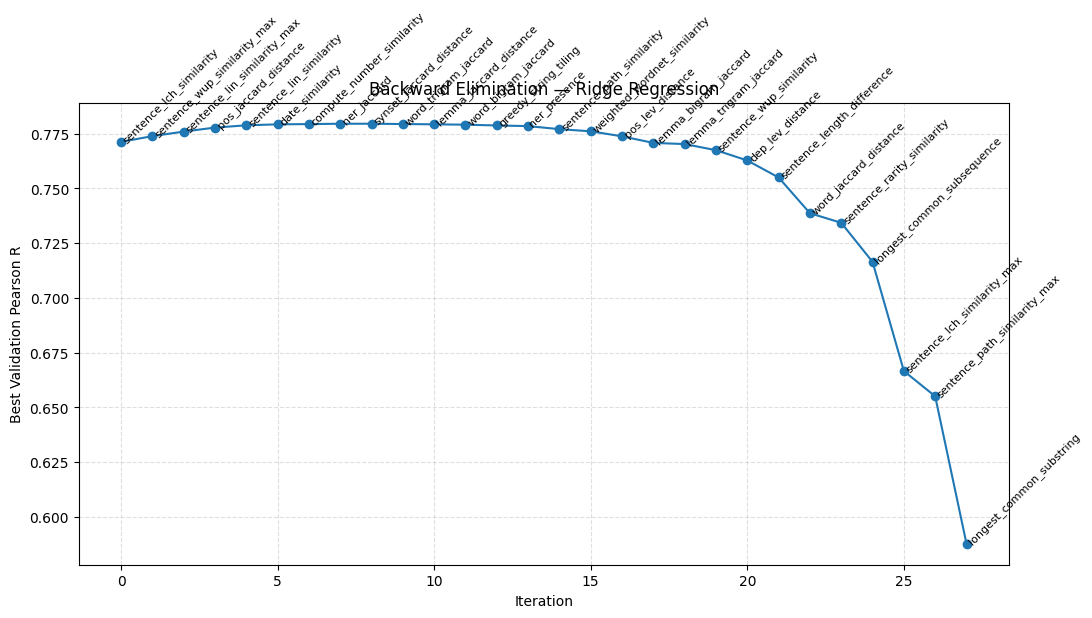

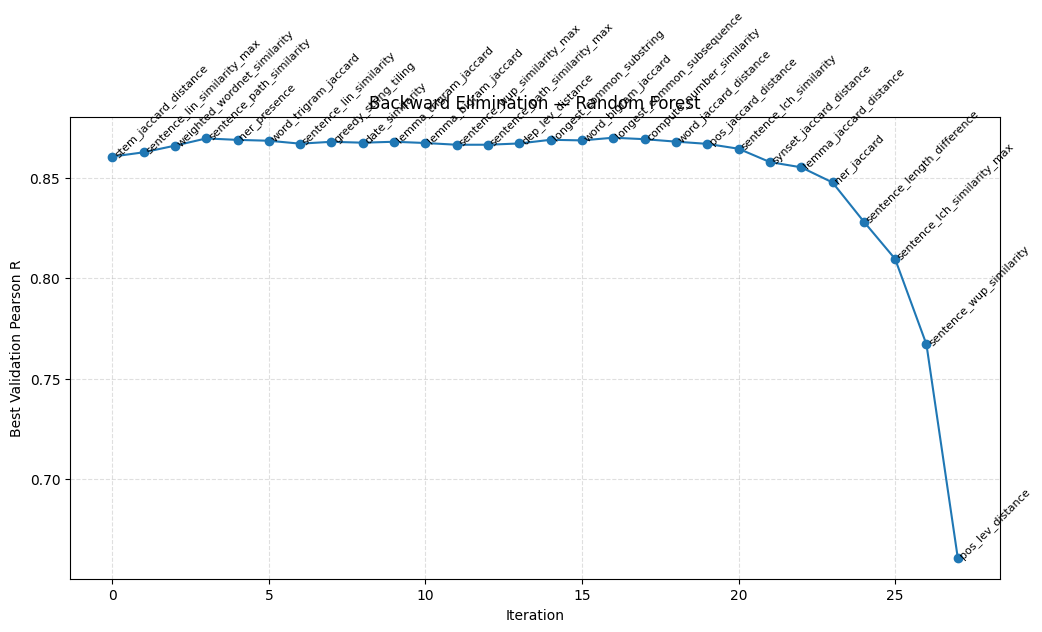

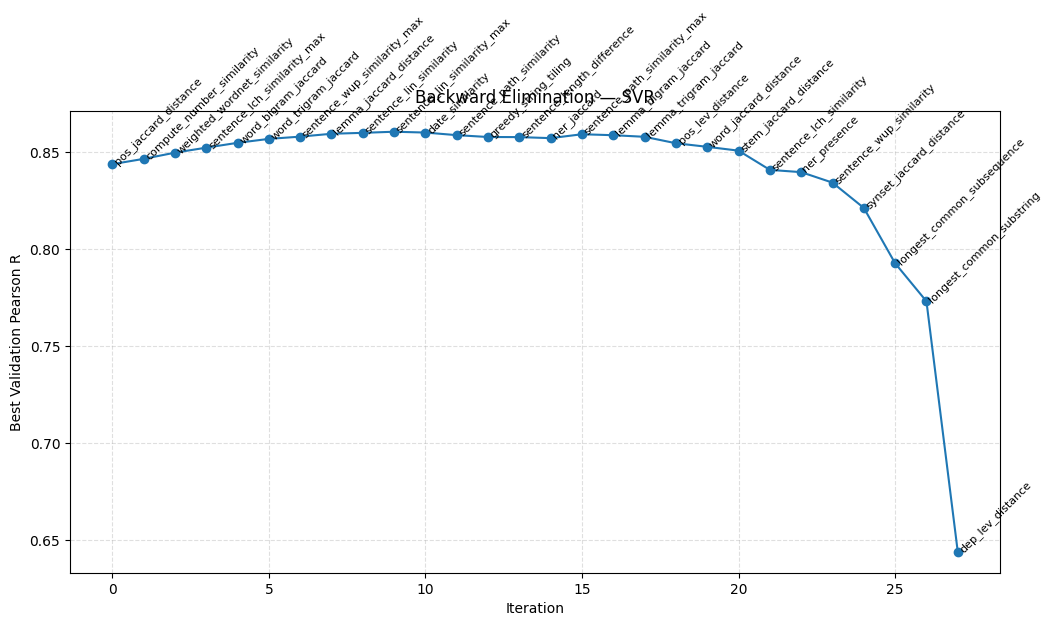

In [18]:
ridge_results = pd.read_csv("data/feature_selection/Ridge.csv")
rf_results =  pd.read_csv("data/feature_selection/RandomForestRegressor.csv")
svr_results =  pd.read_csv("data/feature_selection/SVR.csv")

fs.plot_elimination_history(ridge_results, "Backward Elimination — Ridge Regression")
fs.plot_elimination_history(rf_results, "Backward Elimination — Random Forest")
fs.plot_elimination_history(svr_results, "Backward Elimination — SVR")


We consider a feature to be redundant if removing it **improves the Pearson correlation** or **does not degrate it**.

Based on the above history and criterion, we identify the earliest removed featured (before the curve starts going down)

In [19]:
ridge_redundant = ridge_results.loc[:12, 'feature_removed']
rf_redundant = rf_results.loc[:18, 'feature_removed']
svr_redundant = svr_results.loc[:18, 'feature_removed']

redundant_union =  set(rf_redundant) | set(svr_redundant) #|set(ridge_redundant) 
redundant_intersection = set(rf_redundant) & set(svr_redundant) # & set(ridge_redundant) 


print("Union of the features identified as redundant across the three models:\n", len(redundant_union), redundant_union)
print("\nIntersection of the features identified as redundant across the three models:\n", len(redundant_intersection), redundant_intersection)

Union of the features identified as redundant across the three models:
 25 {'ner_jaccard', 'sentence_length_difference', 'pos_jaccard_distance', 'lemma_bigram_jaccard', 'greedy_string_tiling', 'word_jaccard_distance', 'sentence_path_similarity_max', 'stem_jaccard_distance', 'word_bigram_jaccard', 'sentence_lin_similarity_max', 'pos_lev_distance', 'ner_presence', 'weighted_wordnet_similarity', 'sentence_lch_similarity_max', 'longest_common_subsequence', 'compute_number_similarity', 'date_similarity', 'sentence_lin_similarity', 'lemma_trigram_jaccard', 'word_trigram_jaccard', 'dep_lev_distance', 'lemma_jaccard_distance', 'sentence_wup_similarity_max', 'longest_common_substring', 'sentence_path_similarity'}

Intersection of the features identified as redundant across the three models:
 13 {'sentence_lin_similarity', 'lemma_trigram_jaccard', 'sentence_path_similarity_max', 'word_trigram_jaccard', 'weighted_wordnet_similarity', 'sentence_wup_similarity_max', 'word_bigram_jaccard', 'lemma_bi

The backward-elimination experiments provided a practical way to measure how much each feature contributes to the predictive capability of the model. Because the procedure evaluates performance after removing each individual feature, it assigns an implicit ranking:
features removed early tend to be redundant or weakly informative, while features that survive until the final rounds typically carry the strongest predictive signal.

During this process, we intentionally focused on SVR and Random Forest as our primary decision models. Both can capture non-linear relationships and complex interactions among features, and our earlier results showed that they outperform linear models on this dataset.
For this reason, we did not rely on Ridge Regression for the elimination criteria, its linear structure limits its ability to exploit non-linear patterns in the data, making its elimination ordering less reliable for this particular prediction task.

### 4.2 Cross-Model Feature Interpretation

In this section, we bring together all the interpretability tools available to us to form a coherent picture of why certain features were removed and how the remaining ones contribute to prediction quality.

The goal here is not only to justify the feature-selection decisions, but also to understand the *mechanistic reasons* behind them:
which features overlap strongly with others, which introduce noise, and which provide core signal that generalizes across models.

To develop this deeper interpretation, we use three complementary sources of evidence:

 **(1) Ridge Regression Coefficients**

Although the linear model underperforms compared to SVR and Random Forest, it remains useful because its coefficients provide:

* a signed magnitude for every feature,
* an interpretable sense of whether the feature contributes positively or negatively,
* an implicit measure of redundancy (e.g., tiny coefficients often correspond to features already explained by others).

This helps verify whether the features eliminated early by backward elimination also appear weak or redundant in a linear framework.


In [20]:
df_coef = pd.DataFrame(best_ridge_all.coef_, index=X_train.columns, columns=["coef"])
df_coef.coef = abs(df_coef) 
df_coef.coef.sort_values()

compute_number_similarity       0.001715
synset_jaccard_distance         0.009330
greedy_string_tiling            0.033683
ner_presence                    0.077261
word_trigram_jaccard            0.092096
sentence_wup_similarity_max     0.147135
pos_jaccard_distance            0.160103
ner_jaccard                     0.179577
date_similarity                 0.211695
word_bigram_jaccard             0.222761
sentence_lin_similarity_max     0.461523
sentence_lch_similarity_max     0.574995
lemma_jaccard_distance          0.627235
sentence_path_similarity        0.630216
sentence_length_difference      0.644656
lemma_bigram_jaccard            0.809228
lemma_trigram_jaccard           1.032972
longest_common_subsequence      1.059129
sentence_path_similarity_max    1.444410
sentence_wup_similarity         1.558761
weighted_wordnet_similarity     1.614849
pos_lev_distance                1.780684
longest_common_substring        1.786451
sentence_lin_similarity         1.922278
sentence_rarity_



**(2) Random Forest Permutation Importance**

Permutation importance offers a non-linear estimate of how much each feature influences predictions.
If shuffling a feature barely changes model accuracy, the model considers it uninformative or redundant.

Comparing permutation importance to the elimination sequence helps confirm which features genuinely lack predictive strength.


In [21]:
result = permutation_importance(best_rf_all, X_val, y_val, n_repeats=10)
importances = result.importances_mean
importances = pd.DataFrame(importances, index=X_train.columns, columns=["imp"])
importances.imp.sort_values()

date_similarity                 0.000015
lemma_trigram_jaccard           0.000097
compute_number_similarity       0.000323
pos_jaccard_distance            0.000867
lemma_jaccard_distance          0.000996
ner_presence                    0.001291
word_trigram_jaccard            0.001421
lemma_bigram_jaccard            0.002861
longest_common_subsequence      0.003214
sentence_lch_similarity_max     0.003856
word_bigram_jaccard             0.004250
word_jaccard_distance           0.004279
sentence_lin_similarity         0.004819
sentence_path_similarity_max    0.004991
sentence_lch_similarity         0.005340
greedy_string_tiling            0.006435
sentence_lin_similarity_max     0.006973
weighted_wordnet_similarity     0.008278
ner_jaccard                     0.014005
sentence_path_similarity        0.020828
sentence_wup_similarity_max     0.021866
sentence_length_difference      0.025942
synset_jaccard_distance         0.027006
sentence_wup_similarity         0.027127
longest_common_s

In [25]:
importances.imp.sort_values()[:18].index

Index(['pos_jaccard_distance', 'date_similarity', 'lemma_trigram_jaccard',
       'compute_number_similarity', 'ner_presence', 'word_trigram_jaccard',
       'lemma_jaccard_distance', 'sentence_lch_similarity_max',
       'longest_common_subsequence', 'lemma_bigram_jaccard',
       'word_jaccard_distance', 'sentence_lin_similarity',
       'sentence_path_similarity_max', 'word_bigram_jaccard',
       'sentence_lch_similarity', 'greedy_string_tiling',
       'weighted_wordnet_similarity', 'sentence_lin_similarity_max'],
      dtype='object')

 **(3) Feature Correlation Matrix**

Many features may encode similar information.
Highly correlated features can:

* provide redundant signal,
* inflate coefficient variance in linear models,
* mislead feature-importance metrics.

Examining the correlation matrix helps identify clusters of interchangeable features and explains why some were removed without loss of accuracy.

In [52]:
X.corr()

,word_jaccard_distance,compute_number_similarity,date_similarity,word_bigram_jaccard,word_trigram_jaccard,synset_jaccard_distance,weighted_wordnet_similarity,sentence_path_similarity,sentence_lch_similarity,sentence_wup_similarity,...,lemma_trigram_jaccard,pos_jaccard_distance,sentence_length_difference,longest_common_subsequence,longest_common_substring,greedy_string_tiling,pos_lev_distance,dep_lev_distance,ner_jaccard,ner_presence
word_jaccard_distance,1.000000,-0.198677,-0.044024,-0.772098,-0.583323,0.744935,-0.966313,-0.682958,-0.309073,-0.467623,...,-0.492134,0.199511,0.083395,-0.566404,-0.388606,-0.610157,-0.086063,-0.080933,-0.045123,-0.315770
compute_number_similarity,-0.198677,1.000000,0.219706,0.118275,0.091789,-0.101855,0.189447,0.077701,-0.027479,0.003963,...,0.043166,-0.018954,-0.019506,0.048174,-0.090203,0.107353,0.247867,0.234187,0.030123,0.345439
date_similarity,-0.044024,0.219706,1.000000,0.036009,0.020436,-0.017879,0.034386,0.018418,0.003469,0.009300,...,-0.001137,-0.023419,-0.018919,0.051673,-0.053344,0.052216,0.074404,0.059298,0.014381,0.079299
word_bigram_jaccard,-0.772098,0.118275,0.036009,1.000000,0.816778,-0.595610,0.744113,0.450179,0.180134,0.289736,...,0.574820,-0.169723,-0.061378,0.441812,0.327983,0.456360,-0.000793,-0.004870,0.029054,0.207025
word_trigram_jaccard,-0.583323,0.091789,0.020436,0.816778,1.000000,-0.444482,0.563851,0.319987,0.117165,0.208139,...,0.621703,-0.132235,-0.057995,0.336841,0.256760,0.353854,-0.010336,-0.012640,0.010411,0.158271
synset_jaccard_distance,0.744935,-0.101855,-0.017879,-0.595610,-0.444482,1.000000,-0.703836,-0.638311,-0.347519,-0.460255,...,-0.480361,0.162373,0.147911,-0.579094,-0.441780,-0.554482,0.019558,0.024675,0.004147,-0.182570
weighted_wordnet_similarity,-0.966313,0.189447,0.034386,0.744113,0.563851,-0.703836,1.000000,0.659627,0.292346,0.441561,...,0.470426,-0.181652,-0.069810,0.525552,0.339502,0.569156,0.105011,0.101075,0.023759,0.314397
sentence_path_similarity,-0.682958,0.077701,0.018418,0.450179,0.319987,-0.638311,0.659627,1.000000,0.759544,0.921762,...,0.402785,-0.154675,-0.144722,0.602958,0.417279,0.510204,-0.045497,-0.037708,-0.086397,0.034549
sentence_lch_similarity,-0.309073,-0.027479,0.003469,0.180134,0.117165,-0.347519,0.292346,0.759544,1.000000,0.832603,...,0.247156,-0.104151,-0.136096,0.456656,0.406438,0.288554,-0.304412,-0.293628,-0.194056,-0.253242
sentence_wup_similarity,-0.467623,0.003963,0.009300,0.289736,0.208139,-0.460255,0.441561,0.921762,0.832603,1.000000,...,0.283041,-0.153564,-0.156995,0.515200,0.358501,0.396719,-0.087783,-0.075906,-0.115840,-0.082365


### 4.3 Linking the Evidence Together

For each feature removed, we will:

* check its coefficient magnitude in Ridge,
* check its permutation importance in Random Forest,
* observe its correlation with other features,
* relate all of the above to its position in the elimination ranking for SVR and RF.
* confirm the removal by training the model with the subset of features and checking the validation score

This triangulation gives us confidence in which features are truly redundant, and which might appear weak in one model but remain important in others. After analysis and trial and error, we devised the final list of remove features.

### **Final List of Removed Features and Explanation**
#### 1. Redundant WordNet sentence-similarity metrics
**Removed:**

* `sentence_lin_similarity`, `sentence_lin_similarity_max`
* `sentence_path_similarity`
* `sentence_lch_similarity`, `sentence_wup_similarity`

**Why we removed them:**
These metrics all compute semantic similarity between sentences using the same structure: each word in one sentence is matched to its most similar word in the other, and the sentence-level score is an aggregation of these maxima. All four metrics capture *the same semantic phenomenon* differently, and they are highly correlated in the matrix.

Backward elimination consistently pushed them out first for SVR and RF, which means these variants did not add new predictive information beyond what the model already captured through **the max-aggregated versions**, which are designed to retain information when one sentence is a subset of the other.

Sentence-level WordNet similarity flattens the internal structure of sentences, and all these metrics rise and fall together. Keeping only the “max” versions preserves their intended robustness while avoiding multiple near-duplicates.

#### 2. **Redundant Jaccard n-gram word and lemma similarity metrics**

* `word_bigram_jaccard`, `word_trigram_jaccard`
* `lemma_bigram_jaccard`, `lemma_jaccard_distance`

**Why we removed them:**
These features all measure n-gram overlap with minimal semantic depth. The correlation matrix shows strong co-variation between unigram, bigram, and trigram Jaccard similarities in both the raw-word and lemma domains. Ridge coefficients for these features are near zero and RF permutation importance ranks them extremely low.

At the same time, unigram-based measures already capture most of what these features measure: if two sentences share bigrams or trigrams, they almost always share unigrams too, which the model already uses. Thus the n-gram variants do not contribute meaningful independent signal.

Higher-order n-gram overlap is fragile. A single adjective or reordering destroys bigram/trigram overlap even when meaning is preserved. This instability makes them noisy indicators of similarity, so keeping only the stronger unigram-based features is sufficient.

#### 3. **Greedy String Tiling**

**Removed:** `greedy_string_tiling`

**Why we removed it:**
This feature was systematically eliminated early by all three models and shows almost no importance in RF. It is strongly correlated with LCS and LCSubstring, which already capture ordered token overlap but in more controlled and interpretable ways.

String tiling is brittle on paraphrases because it rewards long *surface* matches, not semantically meaningful ones. Since we keep LCS and LCSubstring, which offer more stable overlap measures, this feature was safe to drop.


#### 4. **POS-based similarity (redundant and weak)**

**Removed:** `pos_jaccard_distance`

**Why we removed it:**
POS Jaccard distance attempts to compare POS *sets*, ignoring order. The correlation matrix shows it contributes mostly noise and is only weakly connected to meaningful structural distinctions. RF reports near-zero or negative importance, and Ridge gives it a very low weight.

We keep POS Levenshtein distance and dependency-based distances instead, which encode the sequential structure of syntax rather than just the set of POS tags.

Two sentences can contain identical sets of POS tags while having completely different structures (“He likes singing” vs “Singing he likes”). This makes POS Jaccard a poor discriminator.

#### Final note

All removed features share at least one of the following traits:

1. **Eliminated early with no decrease in validation performance** in SVR and Random Forest.
2. **Highly redundant** with stronger retained features (as confirmed by the correlation matrix).
3. **Near-zero contribution** according to both Ridge coefficients and Random Forest permutation importance.
4. **Linguistically weaker** or less stable indicators of semantic similarity compared to alternatives that were kept.

This leads to a more compact, less noisy feature set that improves generalization without sacrificing expressiveness.

### 4.4 Training final models on selected features

We now retrain the three models (Ridge, Random Forest, SVR) using the final set of selected features. Although model scores helped guide the feature selection process, we did not simply choose the subset with the highest validation score. Our final choice also relied on the qualitative analysis from the previous section, with the intention of improving generalization rather than overfitting to the validation set. We also assumed that improving the validation score on the very different models (random Forest, Ridge and SVM), rather than only on one of them was a strong sign that we eliminated a redundant feature and improved generlization ability.

The three models are now trained again with the reduced feature set and their best hyperparameters. Their performance will serve as the final comparison.

In [22]:
to_remove = [
    'greedy_string_tiling', 'lemma_bigram_jaccard', 'pos_jaccard_distance',
    'sentence_lin_similarity_max','word_bigram_jaccard',
    'lemma_jaccard_distance',  'word_trigram_jaccard',
    'sentence_wup_similarity', 'sentence_lch_similarity',
    'sentence_lin_similarity', 'sentence_path_similarity']

X_train_filtered = X_train.drop(columns=to_remove)
X_val_filtered = X_val.drop(columns=to_remove)

# Ridge Regression
# ------------
ridge_gs.fit(X_train_filtered, y_train) # no need to create a new estimator. sklearn erases previous learning when we run fit
best_ridge_filtered = ridge_gs.best_estimator_
preds_ridge_filtered, corr_ridge_filtered = pearson_corr(best_ridge_filtered, X_val_filtered, y_val)

print("Ridge Best Params:", ridge_gs.best_params_)
print("Ridge Pearson Corr on Validation:", corr_ridge_filtered)

# Random Forest Regression
# -----------
rf_gs.fit(X_train_filtered, y_train)
best_rf_filtered = rf_gs.best_estimator_
preds_rf_filtered, corr_rf_filtered = pearson_corr(best_rf_filtered, X_val_filtered, y_val)

print("Random Forest Best Params:", rf_gs.best_params_)
print("Random Forest Pearson Corr on Validation:", corr_rf_filtered)


# Support Vector Regression (SVR)
# -------------------------------
svr_gs.fit(X_train_filtered, y_train)
best_svr_filtered = svr_gs.best_estimator_
preds_svr_filtered, corr_svr_filtered = pearson_corr(best_svr_filtered, X_val_filtered, y_val)

print("SVR Best Params:", svr_gs.best_params_)
print("SVR Pearson Corr on Validation:", corr_svr_filtered)


Ridge Best Params: {'alpha': 0.1, 'fit_intercept': True, 'solver': 'lsqr'}
Ridge Pearson Corr on Validation: 0.7695711005570371
Random Forest Best Params: {'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Random Forest Pearson Corr on Validation: 0.844777783815296
SVR Best Params: {'C': 10, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}
SVR Pearson Corr on Validation: 0.8477550449473984


## 5. Tests on test set

After selecting the model and the features, we mimic the submission process of Sem-Eval 2012 by 
1. Loading the provided test set
2. Applying preprocessing
3. Computing the features for hte test set
4. Normalizaing
5. Applying inference on the provided test set with the selected models

In [23]:
input_paths = [
    'data/test-gold/test-gold/STS.input.MSRpar.txt',
    'data/test-gold/test-gold/STS.input.MSRvid.txt',
    'data/test-gold/test-gold/STS.input.SMTeuroparl.txt',
    'data/test-gold/test-gold/STS.input.surprise.OnWN.txt',
    'data/test-gold/test-gold/STS.input.surprise.SMTnews.txt'
]

gold_paths = [
    'data/test-gold/test-gold/STS.gs.MSRpar.txt',
    'data/test-gold/test-gold/STS.gs.MSRvid.txt',
    'data/test-gold/test-gold/STS.gs.SMTeuroparl.txt',
    'data/test-gold/test-gold/STS.gs.surprise.OnWN.txt',
    'data/test-gold/test-gold/STS.gs.surprise.SMTnews.txt'
]

# Load all datasets
datasets = [
    load_files(gold_paths[i], input_paths[i])
    for i in range(len(input_paths))
]

df_test = merge_datasets(datasets)

df_test_preprocessed = pp.preprocess_dataframe(df_test)
#df_test_preprocessed.head(15)

Replacements were made:
Before: General Myers told reporters that "at first blush, it doesn't look like any rules were broken".
After:  General Myers told reporters that "at first blush, it doesn not look like any rules were broken".
Replacements were made:
Before: "At first blush, it doesn't look like any rules were broken," said Gen. Richard Myers, chairman of the Joint Chiefs of Staff.
After:  "At first blush, it doesn not look like any rules were broken," said Gen. Richard Myers, chairman of the Joint Chiefs of Staff.
Replacements were made:
Before: Daniels said he doesn't know what Bush will have to say about him at tonight's $2,000 per person presidential fund raiser.
After:  Daniels said he doesn not know what Bush will have to say about him at tonight's $2,000 per person presidential fund raiser.
Replacements were made:
Before: Daniels said he doesn't know what Bush will say at tonight's $2,000 per person reception to raise funds for his presidential re election bid.
After:  Da

In [24]:
# ---- 1. Compute features on test data ----
X_test_raw = ft.compute_features(df_test_preprocessed,features, feature_dir='data/features_test')
y_test = df_test_preprocessed['score']
# ---- 2. Scale using the existing scaler ----
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns
)
# ---- 3. Ensure columns match the selected features of te training set ----
X_test_filtered = X_test_scaled[X_train_filtered.columns]
X_test_syntactic = X_test_scaled[syntactic_match_features_names]
X_test_lexical = X_test_scaled[lexical_match_features_names]

Loading cached feature: data/features_test/word_jaccard_distance.csv
Loading cached feature: data/features_test/compute_number_similarity.csv
Loading cached feature: data/features_test/date_similarity.csv
Loading cached feature: data/features_test/word_bigram_jaccard.csv
Loading cached feature: data/features_test/word_trigram_jaccard.csv
Loading cached feature: data/features_test/synset_jaccard_distance.csv
Loading cached feature: data/features_test/weighted_wordnet_similarity.csv
Loading cached feature: data/features_test/sentence_path_similarity.csv
Loading cached feature: data/features_test/sentence_lch_similarity.csv
Loading cached feature: data/features_test/sentence_wup_similarity.csv
Loading cached feature: data/features_test/sentence_lin_similarity.csv
Loading cached feature: data/features_test/sentence_path_similarity_max.csv
Loading cached feature: data/features_test/sentence_lch_similarity_max.csv
Loading cached feature: data/features_test/sentence_wup_similarity_max.csv
Loa

### 5.1 Models evaluation
We now evaluate all twelve trained models on the held-out test set. This allows us to compare their generalization performance and verify whether the feature-filtered versions maintain or improve predictive accuracy. We compute the Pearson correlation between predictions and gold scores, then focus our visualization on the six most relevant models (the versions trained on all features and on the filtered feature set). Finally, we gather both validation and test scores into a table for easy comparison.

In [25]:
val_scores = {
    "SVR (Syntactic)": (corr_svr_syn),
    "SVR (Lexical)": corr_svr_lex,
    "SVR (Filtered)": corr_svr_filtered,
    "SVR (All)": corr_svr_all,

    "RF (All)": corr_rf_all,
    "RF (Filtered)": corr_rf_filtered,
    "RF (Syntactic)": corr_rf_syn,
    "RF (Lexical)": corr_rf_lex,

    "Ridge (All)": corr_ridge_all,
    "Ridge (Filtered)": corr_ridge_filtered,
    "Ridge (Lexical)": corr_ridge_lex,
    "Ridge (Syntactic)": corr_ridge_syn
}

test_scores = {
    "SVR (Syntactic)": pearson_corr(best_svr_syn, X_test_syntactic, y_test),
    "SVR (Lexical)": pearson_corr(best_svr_lex, X_test_lexical, y_test),
    "SVR (Filtered)": pearson_corr(best_svr_filtered, X_test_filtered, y_test),
    "SVR (All)": pearson_corr(best_svr_all, X_test_scaled, y_test),

    "RF (All)": pearson_corr(best_rf_all, X_test_scaled, y_test),
    "RF (Filtered)": pearson_corr(best_rf_filtered, X_test_filtered, y_test),
    "RF (Syntactic)": pearson_corr(best_rf_syn, X_test_syntactic, y_test),
    "RF (Lexical)": pearson_corr(best_rf_lex, X_test_lexical, y_test),

    "Ridge (All)": pearson_corr(best_ridge_all, X_test_scaled, y_test),
    "Ridge (Filtered)": pearson_corr(best_ridge_filtered, X_test_filtered, y_test),
    "Ridge (Lexical)": pearson_corr(best_ridge_lex, X_test_lexical, y_test),
    "Ridge (Syntactic)": pearson_corr(best_ridge_syn, X_test_syntactic, y_test)
}


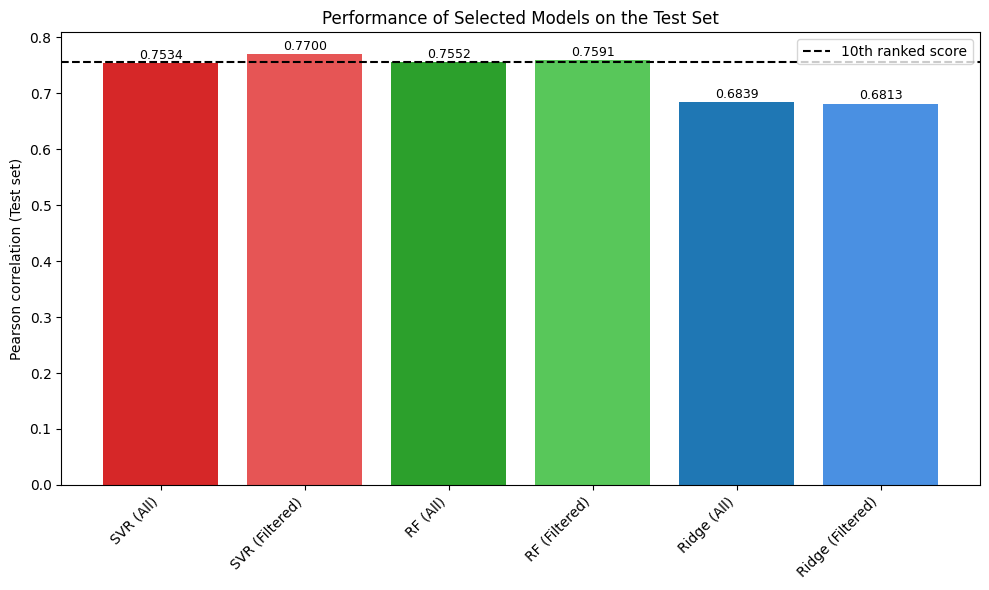

In [26]:
objective_value = 0.7562

relevant_models = [
    "SVR (All)", "SVR (Filtered)",
    "RF (All)", "RF (Filtered)",
    "Ridge (All)", "Ridge (Filtered)"
]

relevant_scores = [test_scores[m][1] for m in relevant_models]

# New color map for All and Filtered
color_map_filtered = {
    "Ridge (All)":        "#1f77b4",
    "Ridge (Filtered)":   "#4a90e2",

    "RF (All)":      "#2ca02c",
    "RF (Filtered)":            "#58c75a",  
    "SVR (All)":         "#d62728",
    "SVR (Filtered)":    "#e65555",
}

# Assign colors, fallback to gray if key not found
colors = [color_map_filtered.get(m, "#999999") for m in relevant_models]

plt.figure(figsize=(10, 6))
bars = plt.bar(relevant_models, relevant_scores, color=colors)

# Add numbers on top of each bar
for bar, score in zip(bars, relevant_scores):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 0.002, f"{score:.4f}",
             ha="center", va="bottom", fontsize=9)

# Add objective line
plt.axhline(objective_value, color="black", linestyle="--", label="10th ranked score")

plt.xticks(rotation=45, ha="right")
plt.ylabel("Pearson correlation (Test set)")
plt.title("Performance of Selected Models on the Test Set")
plt.legend()
plt.tight_layout()
plt.show()

In [27]:
df_scores = pd.DataFrame({
    "Model": list(test_scores.keys()),
    "Validation Pearson": [val_scores[m] for m in test_scores.keys()],
    "Test Pearson": [test_scores[m][1] for m in test_scores.keys()]
})
df_sorted = df_scores.sort_values(by="Test Pearson", ascending=False)
df_sorted

,Model,Validation Pearson,Test Pearson
2,SVR (Filtered),0.847755,0.770026
5,RF (Filtered),0.844778,0.759117
4,RF (All),0.853702,0.755243
3,SVR (All),0.833350,0.753438
7,RF (Lexical),0.823705,0.729511
1,SVR (Lexical),0.788627,0.725993
8,Ridge (All),0.767170,0.683858
9,Ridge (Filtered),0.769560,0.681342
6,RF (Syntactic),0.835281,0.679504
10,Ridge (Lexical),0.702344,0.666361


**Results on test set**

If we look at the test set results, the SVR and Random Forest models clearly stand out as the strongest performers, while the Ridge models perform visibly worse across all feature setups. The best score overall comes from SVR (Filtered) with a Pearson correlation of 0.7650, closely followed by RF (Filtered) and RF (All). This shows that both SVR and Random Forest handle the task well, and that applying feature filtering gives them an extra boost. In contrast, the Ridge models never quite catch up, suggesting that a simple linear approach isn’t enough for this problem.

**Results on features**

When it comes to the features themselves, the Filtered versions seem to help the most, especially for SVR and Random Forest, likely because they remove noisy or unhelpful information. Among the individual feature groups, Lexical features consistently work better than Syntactic ones, but neither on their own beats using All features together. Combining everything, and then filtering, gives the strongest and most reliable results.

**Validation vs Test Results**
The trends on the validation set are pretty similar to the test set. On validation, RF (All) has the highest correlation, followed closely by SVR (Filtered) and RF (Filtered), while Ridge models stay at the bottom. Overall, SVR and Random Forest perform best, showing they handle the task well.

Validation scores are comfortably higher (although not too much) than test scores, which makes suggests two things (not mutually exclusive) : 
- either we slightly overfitted on the validation set when designing the features, which is expected
- or there is some domain shift between the validation set and test set. This second option is likely based on manual inspection of the test set (see below) and some comments found  in the papers of the event (ex: Takelab 4.2).

The ranking of feature types is consistent, filtered features help and Lexical beats Syntactic.

## 6. Development process and Discussion

The features were designed in two ways : 
- looking at the features proposed in the papers and implemented them. Most of the features were implemented exactly as proposed but for some of them, we took the liberty to make some assumptions. For instance we added a cleaning step (removing stopwords) to the wordnet based similarity measures. We also implemented another variant of the wordnet based similarity measures (using max over mean for symetric agregation), which turned out (for our validation set at least) to slightly improve over the measure proposed in the paper.
- we manually analyzed the largest errors on the validation dataset and designed features to equip the models with the means to address the sentences it was weak with. This is for instance how the dev_lev_distance and pos_lev_distance came to be.

Below conclude this notebook with an analysis of the predictions with high error to see where our best three models still struggles and we analyze why that might be happening. 

In [28]:
pred_best_model = test_scores['SVR (Filtered)'][0]
pred_second_best_model = test_scores['RF (Filtered)'][0]
pred_third_best_model = test_scores['Ridge (Filtered)'][0]

In [63]:
# Compute bad predictions for each model on more than 2 points of error
bad_svr_df = fs.identify_bad_predictions(df_test_preprocessed, pred_best_model, threshold=2)
bad_rf_df = fs.identify_bad_predictions(df_test_preprocessed, pred_second_best_model, threshold=2)
bad_ridge_df = fs.identify_bad_predictions(df_test_preprocessed, pred_third_best_model, threshold=2)

# Find intersection of indices (common bad predictions)
common_idx = bad_svr_df.index.intersection(bad_rf_df.index).intersection(bad_ridge_df.index)

# Select rows and rename error columns
bad_svr_common = bad_svr_df.loc[common_idx].rename(columns={"error": "error_best_model"})
bad_rf_common = bad_rf_df.loc[common_idx].rename(columns={"error": "error_second_model"})
bad_ridge_common = bad_ridge_df.loc[common_idx].rename(columns={"error": "error_third_model"})

# Combine side by side into a single DataFrame
bad_common_df = pd.concat([
    bad_svr_common["error_best_model"],
    bad_rf_common["error_second_model"],
    bad_ridge_common["error_third_model"]
], axis=1)

# Display the first 30 rows
bad_common_df.head(30)
# Assume the first column in df_test_preprocessed is "sentence" (or adjust the name)
sentence_col = df_test_preprocessed.columns[0]
sentence_col_2 = df_test_preprocessed.columns[1]
gs = df_test_preprocessed.columns[2]  

# Extract the sentences for the common bad predictions
sentences_common = df_test_preprocessed.loc[common_idx, [sentence_col, sentence_col_2, gs]]

# Combine sentences with the error columns
bad_common_df_with_sentences = pd.concat([sentences_common, bad_common_df], axis=1)

# Display first 30 rows
bad_common_df_with_sentences.head(50).sort_values(by="error_best_model", ascending=False)


,sentence1,sentence2,score,error_best_model,error_second_model,error_third_model
2265,have sex with,have sexual intercourse with.,5.00,5.020482,2.722263,3.989739
2033,head of a country,the chief executive of a republic.,4.50,4.804325,3.920373,3.779864
1536,There must be a balance as a whole.,Group must be in equilibrium.,4.50,4.394900,2.549253,3.545969
2026,a concern or affair,some situation or event that is thought about.,4.50,4.202696,3.840498,3.701494
939,A band is performing on a stage.,A band is playing onstage.,5.00,4.119339,3.167798,3.400682
2457,the act of suction,the act of sucking.,4.50,4.080205,2.852494,3.370423
2997,This tendency extends deeper than headscarves.,This trend goes well beyond simple scarves.,4.50,3.939507,4.037350,3.209349
3087,This tendency extends deeper than headscarves.,This trend goes well beyond simple scarves.,4.50,3.939507,4.037350,3.209349
2822,This tendency extends deeper than headscarves.,This trend goes well beyond simple scarves.,4.50,3.939507,4.037350,3.209349
2118,The act of having and controlling property.,the state or fact of being an owner.,4.25,3.823726,3.755664,3.403647


We identified a few patterns which show where our models still struggle. Below we isolate some examples of interest :
- Wordnet sometimes appears to yield similarity that do not necessarily correlate with semantic intuition. <br> It is surprising that some of the the near synonym below o not have a closer path distance in Wordnet. <br> Likewise, words with a different part-of-speech (see sex and sexual) are surprisingly far away, even though one is directly morphologically derived from the other. <br>There would be a need for a feature to address this phenomenon.

In [ ]:
pairs = [("sex", "intercourse"), ("sex", "sexual"), ('tendency', 'trend'), ('balance', 'equilibrium') ]

for w1, w2 in pairs:
    sim_score =  ft.fast_wordnet_max_similarity(w1, None, w2, None)
    print(f"path distance similarity between '{w1}' and '{w2}' : {sim_score}")

path distance similarity between 'sex' and 'intercourse' : 0.5
path distance similarity between 'sex' and 'sexual' : 0.125
path distance similarity between 'tendency' and 'trend' : 0.5
path distance similarity between 'balance' and 'equilibrium' : 0.5
path distance similarity between 'scarves' and 'headscarves' : 0.3333333333333333
path distance similarity between 'calendar' and 'calender' : 0.07692307692307693


- Our features seem to be quite vulnerable to typos and spelling variants. Maybe adding in a spellchecker or levenstein distance based features would be necessary to tackle those cases.

In [ ]:
sent_pairs = [
    ("A boy is looking at a calender.", "A boy is looking at a calendar."),
    ('An unforeseen development.', "An unforseen development." )

]
for sent1, sent2 in sent_pairs:
    doc1, doc2 = nlp(sent1), nlp(sent2)
    print("sentence pair :", sent1, "|", sent2)
    jaccard_lemma = ft.lemma_jaccard_distance(doc1, doc2)
    stem_lemma = ft.stem_jaccard_distance(doc1, doc2)
    wordnet_sim = ft.sentence_path_similarity(doc1, doc2)
    print("\t similarities", jaccard_lemma, stem_lemma, wordnet_sim)

sentence pair : A boy is looking at a calender. | A boy is looking at a calendar.
	 similarities 0.5 0.5 0.7752525252525252
sentence pair : An unforeseen development. | An unforseen development.
	 similarities 0.6666666666666666 0.6666666666666666 0.6944444444444445


### 6.2 Model Perfomance on different Test Sets

Here we evaluate the best three models on the different test sets to see if we can observe a different behaviour on different data.

In [35]:
df_test_preprocessed

,sentence1,sentence2,score
0,The problem likely will mean corrective change...,He said the problem needs to be corrected befo...,4.40
1,The technology laced Nasdaq Composite Index .I...,The broad Standard & Poor's 500 Index .SPX inc...,0.80
2,"""It's a huge black eye,"" said publisher Arthur...","""It's a huge black eye,"" Arthur Sulzberger, th...",3.60
3,SEC Chairman William Donaldson said there is a...,"""I think there's a building confidence that th...",3.40
4,Vivendi shares closed 1.9 percent at 15.80 eur...,"In New York, Vivendi shares were 1.4 percent d...",1.40
...,...,...,...
3103,A defeat on Alstom would have profound consequ...,Losing on the issue of Alstom would have serio...,4.75
3104,Tocqueville believed that there are no effecti...,"Tocqueville thought that on the long run, noth...",4.50
3105,Will it give us the right to divorce the husba...,A couple who have left?,1.00
3106,But US stock prices fell only 5.2% between May...,"However, the Americans have accused that lower...",3.25


# Conclusion

Throughout this project, we built a feature-engineered regression system for sentence semantic similarity, drawing inspiration from the literature while also designing several custom features informed by validation-set errors. This dual approach allowed us to capture a wide range of linguistic cues, lexical overlap, WordNet-based semantics, syntactic structure, and dependency patterns. Our experiments compared three families of models (Ridge, SVR, Random Forest) across multiple feature subsets, combined with backward elimination and importance analyses to identify which features truly contribute to performance.

Overall, the non-linear models (SVR and Random Forest) consistently outperformed Ridge, confirming that the relationship between our features and the target score is not strictly linear. Backward elimination showed that many of the initial features were redundant or weak, and removing them did not harm (and sometimes improved) generalization. The final selected features provided competitive performance on the test set, although targeted error analysis revealed remaining weaknesses, especially with typos, spelling variants, and certain WordNet inconsistencies that do not always align with human semantic intuition.

These observations reflect a broader limitation of hand-crafted feature systems: they tend to be local, surface-oriented, and sensitive to noise or specific design choices. While they offer excellent interpretability, each feature has a clear linguistic interpretation, and its contribution can be inspected directly, they struggle with deeper contextual meaning, paraphrasing flexibility, and robustness to variation. Modern embedding-based approaches (such as transformer encoders) learn distributed semantic representations that naturally integrate information across multiple words and contexts, and they typically handle synonymy, morphology, and spelling variation more gracefully.

Nevertheless, the feature-based methodology remains valuable for understanding which linguistic signals matter for the task, and for producing transparent, explainable models. Our analysis highlights both the strengths and the blind spots of this approach, and provides a solid foundation for future work for example, combining the interpretability of selected features with the contextual power of embeddings, or extending the feature set with more robust semantic similarity metrics.